# Customer Churn Prediction

## Project Overview

This project focuses on predicting customer churn using Machine Learning techniques.

Customer churn occurs when customers stop using a company's products or services. Identifying customers who are likely to leave can help businesses develop effective customer retention strategies.

The main objective of this project is to build a classification model that predicts whether a customer is likely to churn based on demographic information, service usage, subscription details, and customer support interactions.

## Objectives

- Perform Exploratory Data Analysis (EDA).
- Handle missing values and categorical features.
- Investigate class imbalance.
- Train and compare Machine Learning models.
- Optimize a Random Forest classifier using RandomizedSearchCV.
- Evaluate model performance using appropriate classification metrics.
- Analyze feature importance.
- Save the final trained model for future deployment.

## Dataset Features

| Feature | Description |
|---|---|
| Age | Customer age |
| Tenure | Duration of customer relationship |
| MonthlyCharges | Monthly service charges |
| SupportCalls | Number of customer support calls |
| ContractType | Customer contract type |
| InternetService | Internet service type |
| PaymentMethod | Customer payment method |
| Churn | Target variable |

## Machine Learning Approach

This is a supervised binary classification problem.

The target variable contains two classes:

- `Yes`: Customer churned.
- `No`: Customer did not churn.

The final model is a Random Forest Classifier optimized through hyperparameter tuning.

## 2. Import Libraries

In [154]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Model selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

# Machine learning model
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer,
    recall_score,
    precision_score
)

# Hyperparameter distributions
from scipy.stats import randint

# Model persistence
import joblib

# Matplotlib settings
print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Load Dataset

In this section, we load the customer churn dataset and perform an initial inspection of its structure.

The dataset contains customer information, service details, and the target variable used for churn prediction.

In [143]:
# Load dataset
df = pd.read_csv("customer_churn.csv")

# Display first five rows
display(df.head())

,Age,Tenure,MonthlyCharges,SupportCalls,ContractType,InternetService,PaymentMethod,Churn
0,56,16,38.190,4,Yearly,Fiber,Bank Transfer,No
1,69,39,54.570,2,Yearly,DSL,Credit Card,No
2,46,5,109.680,1,Yearly,Fiber,Credit Card,Yes
3,32,22,67.400,8,Yearly,DSL,Bank Transfer,Yes
4,60,29,86.760,8,Yearly,DSL,Credit Card,Yes


In [144]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (500, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              500 non-null    int64  
 1   Tenure           500 non-null    int64  
 2   MonthlyCharges   500 non-null    float64
 3   SupportCalls     500 non-null    int64  
 4   ContractType     500 non-null    str    
 5   InternetService  428 non-null    str    
 6   PaymentMethod    500 non-null    str    
 7   Churn            500 non-null    str    
dtypes: float64(1), int64(3), str(4)
memory usage: 31.4 KB

Statistical Summary:


,Age,Tenure,MonthlyCharges,SupportCalls,ContractType,InternetService,PaymentMethod,Churn
count,500.000,500.000,500.000,500.000,500,428,500,500
unique,NaN,NaN,NaN,NaN,3,2,3,2
top,NaN,NaN,NaN,NaN,Monthly,Fiber,Credit Card,Yes
freq,NaN,NaN,NaN,NaN,256,226,179,407
mean,44.220,30.596,68.337,3.938,NaN,NaN,NaN,NaN
std,15.036,17.364,28.893,2.624,NaN,NaN,NaN,NaN
min,18.000,1.000,20.460,0.000,NaN,NaN,NaN,NaN
25%,32.000,16.000,43.082,2.000,NaN,NaN,NaN,NaN
50%,45.000,30.000,67.185,4.000,NaN,NaN,NaN,NaN
75%,57.000,47.000,93.355,6.000,NaN,NaN,NaN,NaN


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset, identify missing values, examine feature distributions, and discover potential patterns before building the machine learning model.

In [145]:
# Check missing values
df.isnull().sum()

Age                 0
Tenure              0
MonthlyCharges      0
SupportCalls        0
ContractType        0
InternetService    72
PaymentMethod       0
Churn               0
dtype: int64

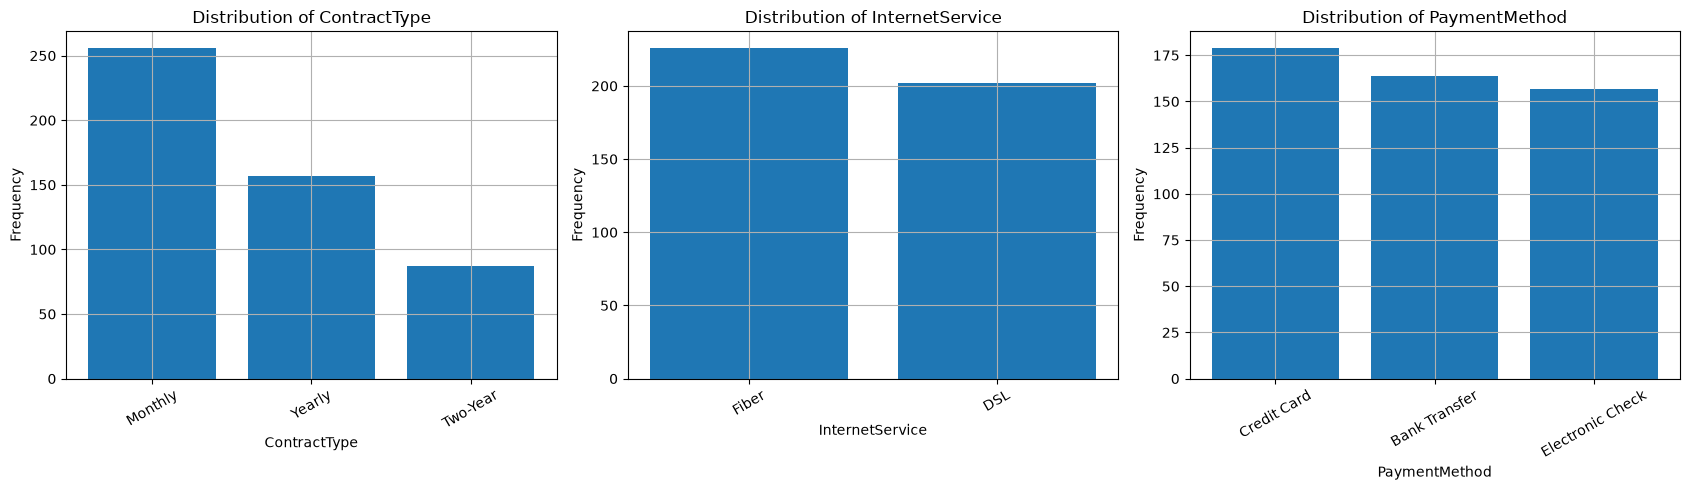

In [146]:
categorical_features = [
    "ContractType",
    "InternetService",
    "PaymentMethod"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for feature, ax in zip(categorical_features, axes):
    counts = df[feature].value_counts()

    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

Data preprocessing is an essential step in preparing raw data for machine learning.

In this project, we use separate preprocessing strategies for numerical and categorical features.

- **Numerical Features:** Missing values are replaced using the median.
- **Categorical Features:** Missing values are replaced using the most frequent value.
- **Encoding:** Categorical variables are transformed into numerical representations using One-Hot Encoding.

We use `ColumnTransformer` and `Pipeline` to ensure consistent preprocessing and prevent data leakage.

In [147]:
# Define numerical and categorical features

numerical_features = [
    "Age",
    "Tenure",
    "MonthlyCharges",
    "SupportCalls"
]

categorical_features = [
    "ContractType",
    "InternetService",
    "PaymentMethod"
]

target = "Churn"

In [148]:
# Numerical preprocessing

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [149]:
# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 4. Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the data is used for model training.
- 20% is reserved for final model evaluation.

We use stratified sampling to preserve the original class distribution in both sets. This is particularly important because the target variable is imbalanced.

In [150]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=4,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (400, 7)
Testing set shape: (100, 7)


In [151]:
# Check target distribution

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Target Distribution:
Churn
Yes    326
No      74
Name: count, dtype: int64

Testing Target Distribution:
Churn
Yes    81
No     19
Name: count, dtype: int64


## 5. Model Development — Random Forest

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve predictive performance and reduce overfitting.

In this project, Random Forest is used to predict whether a customer is likely to churn.

The model is integrated with the preprocessing pipeline to ensure that all transformations are applied consistently during training and prediction.

In [152]:
# Create Random Forest pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=4,
        n_jobs=-1
    ))
])

# Train the model

rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 6. Cross Validation

Cross-validation provides a more reliable estimate of model performance by evaluating it across multiple training and validation splits.

In this project, we use Stratified K-Fold Cross Validation with five folds to preserve the class distribution in each fold.

The evaluation focuses on:

- Accuracy
- Precision
- Recall
- F1-score
- Macro F1-score

Macro F1 is particularly important because the dataset contains an imbalanced target variable.

In [155]:
# Define Stratified K-Fold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics

scoring = {
    "accuracy": "accuracy",
    "precision_yes": make_scorer(
        precision_score,
        pos_label="Yes"
    ),
    "recall_yes": make_scorer(
        recall_score,
        pos_label="Yes"
    ),
    "f1_yes": make_scorer(
        f1_score,
        pos_label="Yes"
    ),
    "f1_macro": "f1_macro"
}

In [156]:
# Evaluate baseline model using cross-validation

cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display cross-validation results

cv_summary = pd.DataFrame({
    "Metric": scoring.keys(),
    "Mean Score": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring.keys()
    ],
    "Standard Deviation": [
        cv_results[f"test_{metric}"].std()
        for metric in scoring.keys()
    ]
})

display(cv_summary)

,Metric,Mean Score,Standard Deviation
0,accuracy,0.828,0.020
1,precision_yes,0.851,0.015
2,recall_yes,0.957,0.027
3,f1_yes,0.900,0.012
4,f1_macro,0.623,0.053


## 7. Handling Class Imbalance

The target variable contains an imbalanced distribution of customer churn labels.

A model trained on imbalanced data may favor the majority class and perform poorly on the minority class.

To address this issue, we experiment with different class weights in the Random Forest classifier.

We compare the models using Macro F1-score and Weighted F1-score to identify a suitable class-weight configuration.

In [162]:
# Define different class weight configurations

class_weights = [
    None,
    "balanced",
    {"Yes": 1, "No": 1.5},
    {"Yes": 1, "No": 2},
    {"Yes": 1, "No": 3}
]

results = []

for weight in class_weights:

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight=weight,
            random_state=4,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["f1_macro", "f1_weighted"],
        n_jobs=-1
    )

    results.append({
        "Class Weight": str(weight),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Weighted F1": scores["test_f1_weighted"].mean()
    })

weight_results = pd.DataFrame(results)

display(
    weight_results.sort_values(
        by="Macro F1",
        ascending=False
    )
)

,Class Weight,Macro F1,Weighted F1
3,"{'Yes': 1, 'No': 2}",0.641,0.799
1,balanced,0.637,0.784
4,"{'Yes': 1, 'No': 3}",0.633,0.787
0,None,0.623,0.798
2,"{'Yes': 1, 'No': 1.5}",0.623,0.795


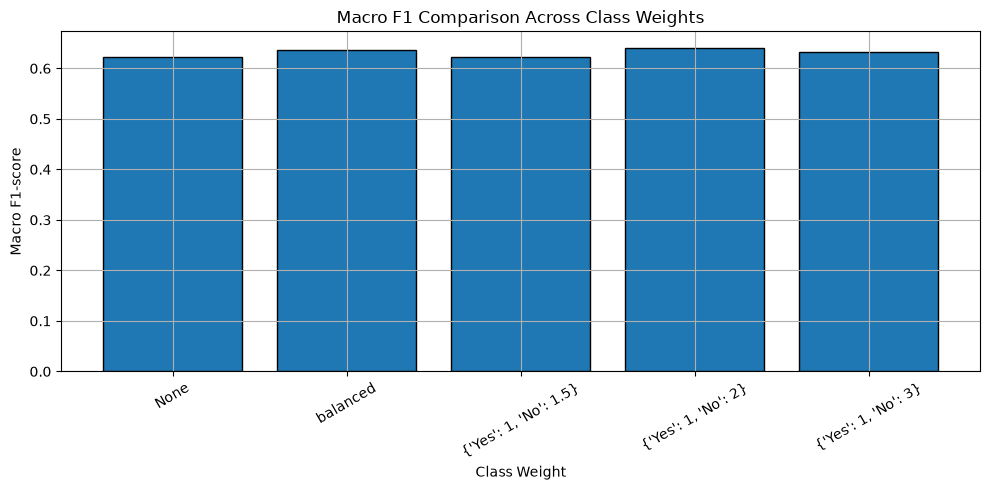

In [163]:
plt.figure(figsize=(10, 5))

plt.bar(
    weight_results["Class Weight"],
    weight_results["Macro F1"],
    edgecolor="black"
)

plt.title("Macro F1 Comparison Across Class Weights")
plt.xlabel("Class Weight")
plt.ylabel("Macro F1-score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()